# Ball-drive risk

A carry-loss probability is assembled from defender-specific arrival probabilities and a shared survival mass. This toy visualization varies speed and nearest pitch-boundary distance using the solver’s actual intensity form. **own derivation**

## Model and inputs

The solver evaluates every defender’s arrival CDF at the carrier’s extrapolated position x_bc(t)=x_bc(0)+v_bc t. For defender i, F_i(t)=σ[π(t−τ_i)/(√3 s)]. The arrival time starts from distance d and speed v₀: t_a=max((v_max−v₀)/a_max,0), d_a=v₀t_a+½a_max t_a². If d≤d_a, t_move=(−v₀+√(v₀²+2a_max d))/a_max; otherwise t_move=t_a+(d−d_a)/v_max. The solver adds rotation time τ_θ=||v||θ/a_max, with θ the angle between current velocity and target direction, and sets τ_i=0 when d is below the near-target threshold. Each defender CDF is therefore based on its own position, velocity, distance, and direction. **own derivation** The common unlost mass is U=clip(1−Σ_i P_i,0,1); each defender contributes dP_i=U F_i(t) λ_def dt, and all increments compete for the same U. Final drive risk is Σ_i P_i. There is no nearest-defender-only reduction in the current solver. **own derivation** The implemented intensity is λ_def=λ₀ exp(β_v ||v_bc|| + β_B x_B), where x_B is the minimum distance to any of the four pitch boundaries. The frame-level drive risk is Σ_i P_i at the requested horizon. The solver uses a discrete Euler update. **own derivation**. In the implementation λ_control is used by pass control; the drive baseline is called lambda_0.

## Usage and visual

The following code uses deterministic synthetic inputs. Any printed quantities and figure values are computed by this cell; no match-level data are embedded.

## Component scope and model limits

Spearman-style arrival distributions motivate the probabilistic motion component [@spearman2017; @bekkers2025]. This implementation’s boundary covariate and hazard intensity are **own derivation**.

This drive formulation holds the carrier velocity fixed over the integration horizon and represents boundary proximity by distance to the nearest of four pitch boundaries. It does not use only the touchline. The output is the sum of defender-specific probabilities at the chosen horizon. **model scope**


/Users/riccardobergamin/Documents/GitHub/PRESS-portfolio-work/vignettes/01_ball_drive_risk/01_ball_drive_risk.ipynb:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ]


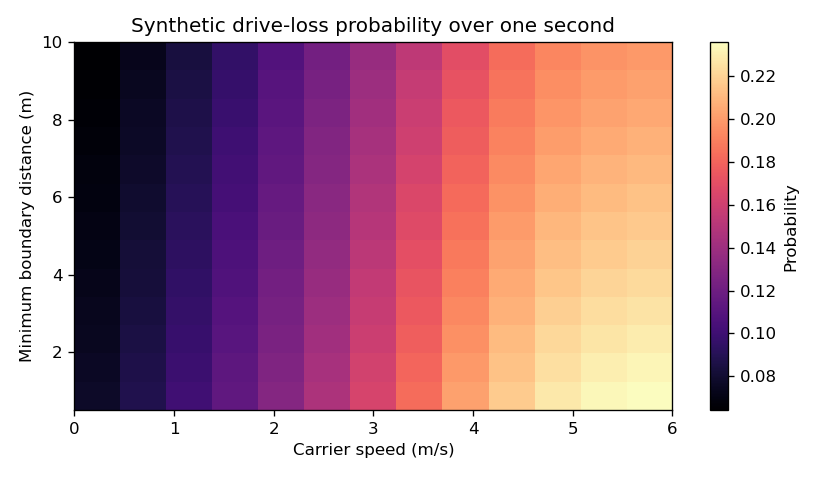

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.model.solver_intensity import integrate_loss_prob

def risk(speed, boundary_distance):
    # Synthetic geometry: two defenders, fixed positions and velocities.
    carrier = np.array([-52.5 + boundary_distance, 0.0])
    defenders = carrier[None, :] + np.array([[3.5, 0.0], [0.0, 5.0]])
    velocities = np.zeros_like(defenders)
    carrier_v = np.array([[speed, 0.0]])
    probs = integrate_loss_prob(defenders, velocities, carrier, carrier_v[0],
        delta_t=1.0, lambda_0=0.36, beta_v=0.09, beta_B=-0.02,
        s=0.43, v_max=7.0, a_max=7.0, dt=0.04)
    return float(np.asarray(probs).sum())
speeds = np.linspace(0, 6, 13)
distances = np.linspace(0.5, 10, 13)
Z = np.array([[risk(v, d) for v in speeds] for d in distances])
fig, ax = plt.subplots(figsize=(7, 4))
image=ax.imshow(Z, origin="lower", aspect="auto", extent=[speeds.min(), speeds.max(), distances.min(), distances.max()], cmap="magma")
ax.set(xlabel="Carrier speed (m/s)", ylabel="Minimum boundary distance (m)", title="Synthetic drive-loss probability over one second")
fig.colorbar(image, ax=ax, label="Probability")
fig.tight_layout()
out=Path("figures/vignette_01_drive_risk.png"); out.parent.mkdir(exist_ok=True); fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
plt.show()